# Group 3 — Heart Disease Prediction (Binary Classification)

**Objective:** Predict whether a record indicates the presence of heart disease (`target = 1`) or absence (`target = 0`) using the uploaded `heart.csv` dataset.

**Models**
1. Logistic Regression (Scikit-learn)
2. Neural Network (TensorFlow/Keras)

**Dataset inspected:** 1,025 rows and 14 columns, with no missing values. The file contains 723 exact duplicate rows, leaving 302 unique records after deduplication. We remove exact duplicates **before splitting** to reduce the risk of identical records appearing in both train and test sets. This means results may differ from studies that use all 1,025 rows.

> **Health disclaimer:** This is a student learning project, not a medical diagnostic system. It must not be used to make medical decisions.


GROUP 3 MEMBERS
1. AMINUDEEN ADAM
2. USMAN ABDULAZEEZ

## 1. Install and import libraries

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn tensorflow

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

# 2. Uploading the dataset

In [3]:
df = pd.read_csv("heart.csv")

print("Original dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())
display(df.describe().T)
print("\nMissing values by column:")
display(df.isna().sum().to_frame("missing_values"))
print("\nTarget counts (0 = no heart disease, 1 = heart disease):")
display(df["target"].value_counts().sort_index().to_frame("count"))
print("\nExact duplicate rows:", df.duplicated().sum())

Original dataset shape: (1025, 14)
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2



Missing values by column:


,missing_values
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0



Target counts (0 = no heart disease, 1 = heart disease):


,count
target,
0,499
1,526



Exact duplicate rows: 723


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


## 3. Data quality and duplicates

This uploaded file has 1,025 rows and 14 columns, with `target` as the label. It has no missing values, but contains many exact duplicate rows. Exact duplicates can make evaluation look overly optimistic if identical records land in both training and test sets, so we remove them before splitting.

The dataset's coded fields (such as `cp`, `restecg`, `slope`, `ca`, and `thal`) are treated as categorical variables. This avoids incorrectly assuming that the category codes are continuous measurements.

In [9]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing exact duplicates:", df.shape)
print("\nTarget counts after deduplication:")
display(df["target"].value_counts().sort_index().to_frame("count"))
print("\nTarget proportions (%):")
display((df["target"].value_counts(normalize=True).sort_index() * 100).round(2).to_frame("percent"))

Shape after removing exact duplicates: (302, 14)

Target counts after deduplication:


,count
target,
0,138
1,164



Target proportions (%):


,percent
target,
0,45.7
1,54.3


## 4. Exploratory Data Analysis (EDA)

### 4.1 Target distribution

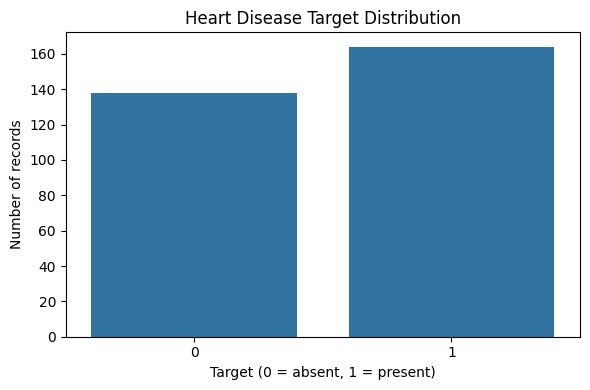

In [10]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="target")
plt.title("Heart Disease Target Distribution")
plt.xlabel("Target (0 = absent, 1 = present)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

### 4.2 Examine important features

The following plots compare age, cholesterol (`chol`), and maximum heart rate (`thalach`) across target classes.

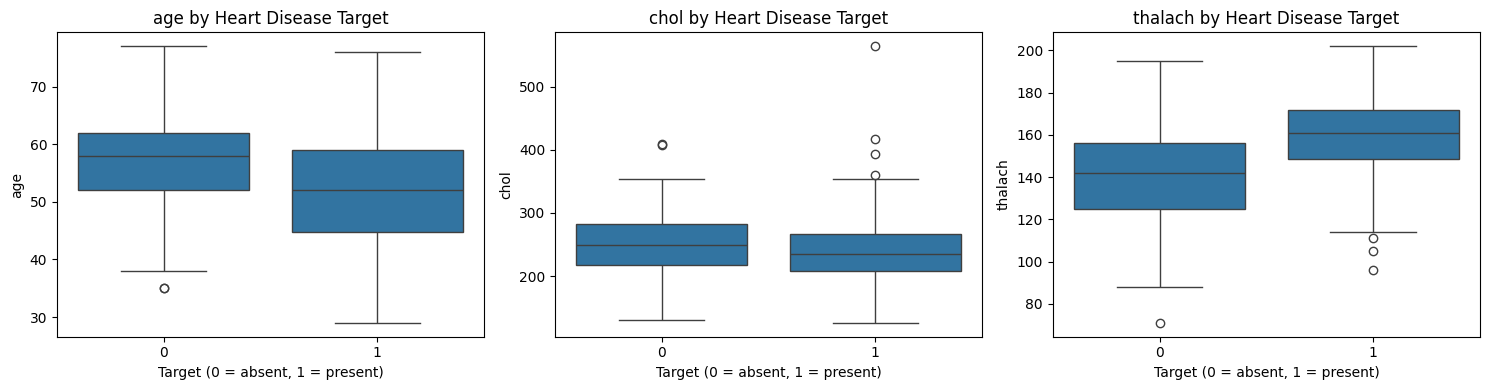

,age,chol,thalach,trestbps,oldpeak
target,,,,,
0,56.60,251.09,139.10,134.40,1.59
1,52.59,242.64,158.38,129.25,0.59


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["age", "chol", "thalach"]):
    sns.boxplot(data=df, x="target", y=col, ax=ax)
    ax.set_title(f"{col} by Heart Disease Target")
    ax.set_xlabel("Target (0 = absent, 1 = present)")
plt.tight_layout()
plt.show()

display(df.groupby("target")[["age", "chol", "thalach", "trestbps", "oldpeak"]].mean().round(2))

### 4.3 Correlation heatmap

Correlation is a measure of linear association, not proof of causation. The heatmap is useful for initial exploration, but category codes are not necessarily ordered measurements.

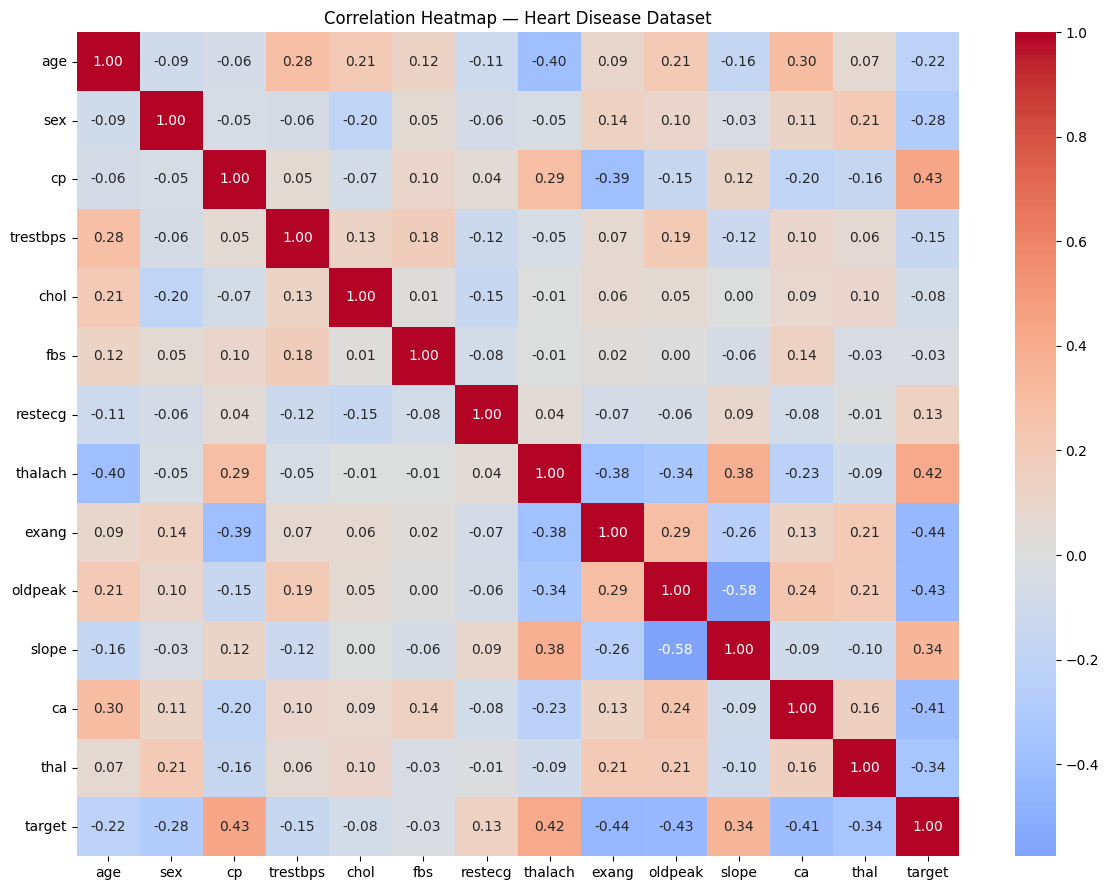

Correlation with target:


,correlation_with_target
target,1.000000
cp,0.432080
thalach,0.419955
slope,0.343940
restecg,0.134874
fbs,-0.026826
chol,-0.081437
trestbps,-0.146269
age,-0.221476
sex,-0.283609


In [12]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap — Heart Disease Dataset")
plt.tight_layout()
plt.show()

print("Correlation with target:")
display(corr["target"].sort_values(ascending=False).to_frame("correlation_with_target"))

## 5. Prepare features and split the data

We use an 80% training set and a 20% test set, with stratification so each split keeps a similar target proportion. The preprocessing steps are fitted on the training set only to prevent data leakage.

- **Numeric features:** `age`, `trestbps`, `chol`, `thalach`, `oldpeak`
- **Categorical coded features:** `sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca`, `thal`

Numeric features are median-imputed if needed and standardized. Categorical features are mode-imputed if needed and one-hot encoded.

In [13]:
target_col = "target"
X = df.drop(columns=[target_col]).copy()
y = df[target_col].astype(int).copy()

numeric_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Convert sparse matrices to dense arrays for TensorFlow.
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()
if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

X_train_processed = np.asarray(X_train_processed, dtype=np.float32)
X_test_processed = np.asarray(X_test_processed, dtype=np.float32)

print("Training shape:", X_train_processed.shape)
print("Test shape:", X_test_processed.shape)

Training shape: (241, 30)
Test shape: (61, 30)


## 6. Handle class imbalance

After removing duplicates, check whether the target classes are imbalanced. Class weights give greater importance to the less frequent class during training. If the classes are already close in size, the weights will be close to one.

In [14]:
classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = {int(cls): float(weight) for cls, weight in zip(classes, weights)}
print("Training class counts:")
display(y_train.value_counts().sort_index().to_frame("count"))
print("Class weights:", class_weights)

Training class counts:


,count
target,
0,110
1,131


Class weights: {0: 1.0954545454545455, 1: 0.9198473282442748}


## 7. Model 1 — Logistic Regression (Scikit-learn)

In [15]:
sk_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)
sk_model.fit(X_train_processed, y_train)

sk_pred = sk_model.predict(X_test_processed)
sk_prob = sk_model.predict_proba(X_test_processed)[:, 1]

print("Logistic Regression report:")
print(classification_report(
    y_test, sk_pred,
    target_names=["No heart disease (0)", "Heart disease (1)"],
    zero_division=0
))
print("ROC-AUC:", round(roc_auc_score(y_test, sk_prob), 3))

Logistic Regression report:
                      precision    recall  f1-score   support

No heart disease (0)       0.83      0.89      0.86        28
   Heart disease (1)       0.90      0.85      0.88        33

            accuracy                           0.87        61
           macro avg       0.87      0.87      0.87        61
        weighted avg       0.87      0.87      0.87        61

ROC-AUC: 0.905


## 8. Model 2 — TensorFlow/Keras Neural Network

The network has two hidden layers with ReLU activation and one sigmoid output neuron. The sigmoid output estimates the probability of target class 1. Early stopping helps reduce overfitting.

In [22]:
nn_model = keras.Sequential([
    layers.Input(shape=(X_train_processed.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

nn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=15, restore_best_weights=True
)

history = nn_model.fit(
    X_train_processed, y_train,
    validation_split=0.20,
    epochs=150,
    batch_size=16,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)

nn_prob = nn_model.predict(X_test_processed, verbose=0).ravel()
nn_pred = (nn_prob >= 0.5).astype(int)

print("TensorFlow Neural Network report:")
print(classification_report(
    y_test, nn_pred,
    target_names=["No heart disease (0)", "Heart disease (1)"],
    zero_division=0
))
print("ROC-AUC:", round(roc_auc_score(y_test, nn_prob), 3))

Epoch 1/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - accuracy: 0.4896 - loss: 0.7730 - precision: 0.5104 - recall: 0.4900 - val_accuracy: 0.7551 - val_loss: 0.6362 - val_precision: 0.7879 - val_recall: 0.8387
Epoch 2/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5417 - loss: 0.6877 - precision: 0.5667 - recall: 0.5100 - val_accuracy: 0.7959 - val_loss: 0.6065 - val_precision: 0.8387 - val_recall: 0.8387
Epoch 3/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6406 - loss: 0.6268 - precision: 0.6667 - recall: 0.6200 - val_accuracy: 0.8571 - val_loss: 0.5810 - val_precision: 0.8750 - val_recall: 0.9032
Epoch 4/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6927 - loss: 0.6306 - precision: 0.6952 - recall: 0.7300 - val_accuracy: 0.8776 - val_loss: 0.5543 - val_precision: 0.9032 - val_recall: 0.9032
Epoch 5/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6875 - loss: 0.5899 - precision: 0.7041 - recall: 0.6900 - val_accuracy: 0.8776 - val_loss: 0.

### 8.1 Training curves

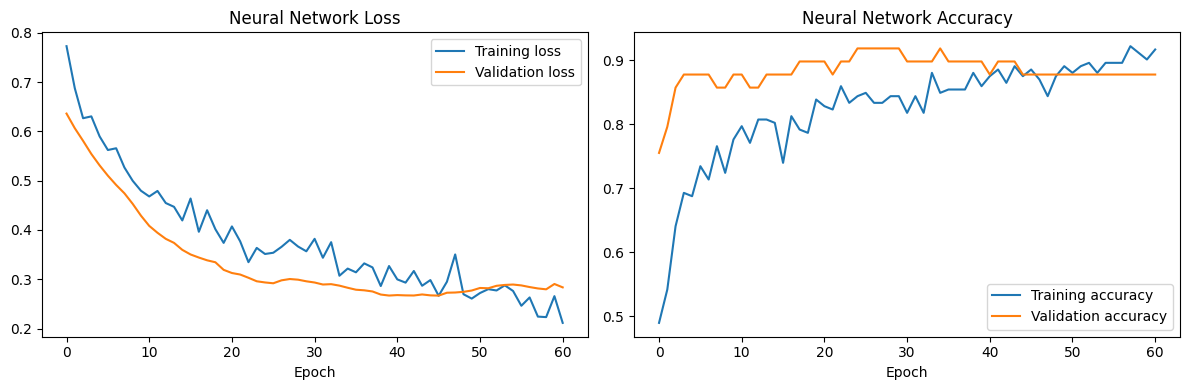

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Neural Network Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Training accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Neural Network Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

## 9. Compare both models

- **Accuracy:** fraction of all predictions that are correct.
- **Precision:** among records predicted as heart disease, the fraction actually labeled positive.
- **Recall:** among positive records, the fraction the model correctly identifies.
- **F1-score:** harmonic mean of precision and recall.
- **ROC-AUC:** how well predicted probabilities rank positive cases above negative cases.

For a health-related model, do not choose a model based on accuracy alone. Examine recall and false negatives as well.

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.869,0.903,0.848,0.875,0.905
TensorFlow Neural Network,0.820,0.844,0.818,0.831,0.879


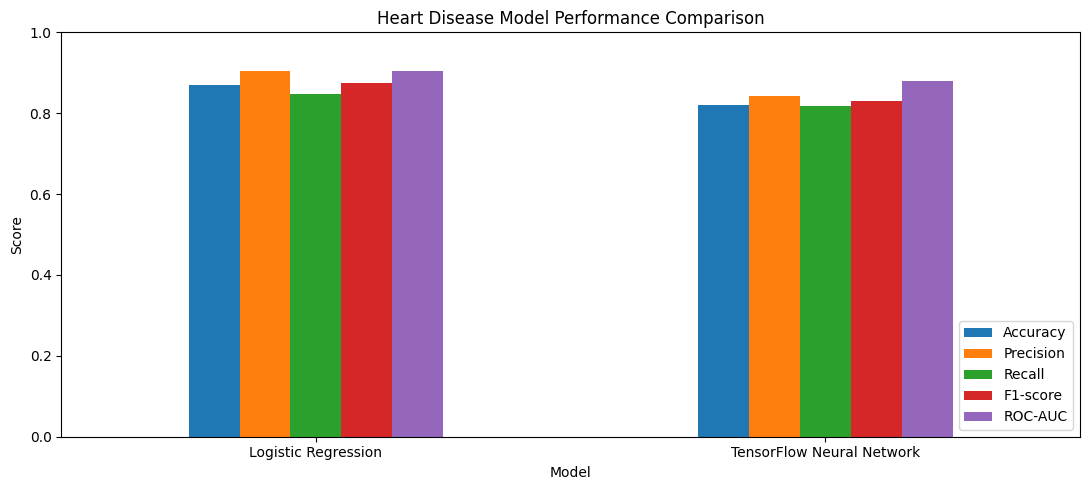

In [24]:
def metric_row(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

results = pd.DataFrame([
    metric_row("Logistic Regression", y_test, sk_pred, sk_prob),
    metric_row("TensorFlow Neural Network", y_test, nn_pred, nn_prob)
]).set_index("Model")

display(results.round(3))
results.plot(kind="bar", figsize=(11, 5), ylim=(0, 1), rot=0)
plt.title("Heart Disease Model Performance Comparison")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 10. Confusion matrices and interpretation

Each confusion matrix is arranged as `[[TN, FP], [FN, TP]]`:
- **True Negative (TN):** correctly predicted target 0.
- **False Positive (FP):** predicted target 1, but actual target is 0.
- **False Negative (FN):** predicted target 0, but actual target is 1.
- **True Positive (TP):** correctly predicted target 1.

False negatives are positive cases the model misses. False positives are negative cases the model incorrectly flags. Both matter and should be discussed.

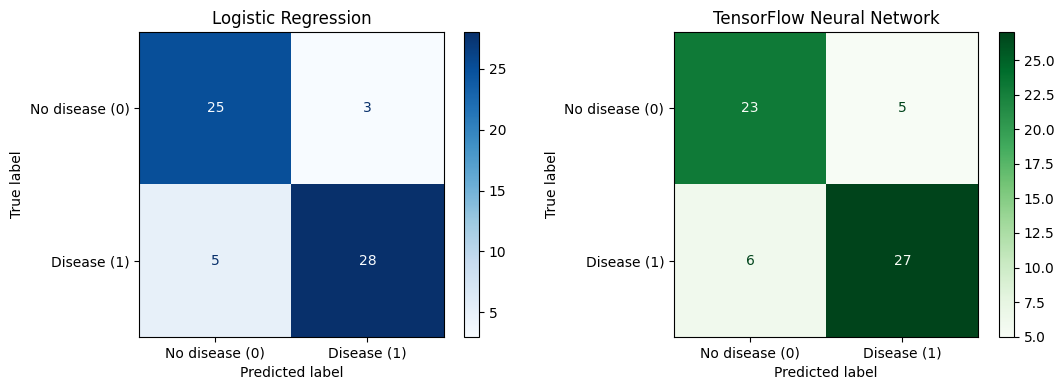


Logistic Regression: TN=25, FP=3, FN=5, TP=28

TensorFlow Neural Network: TN=23, FP=5, FN=6, TP=27


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, sk_pred,
    display_labels=["No disease (0)", "Disease (1)"],
    cmap="Blues", values_format="d", ax=axes[0]
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test, nn_pred,
    display_labels=["No disease (0)", "Disease (1)"],
    cmap="Greens", values_format="d", ax=axes[1]
)
axes[1].set_title("TensorFlow Neural Network")

plt.tight_layout()
plt.show()

for name, pred in [("Logistic Regression", sk_pred), ("TensorFlow Neural Network", nn_pred)]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    print(f"\n{name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

## 11. Conclusion template

In this project, we developed two binary classification models to predict the presence of heart disease using a dataset containing 1,025 rows and 14 columns. After removing 723 duplicate rows, 302 unique records remained.

We performed Exploratory Data Analysis (EDA) to understand the dataset and examine relationships between features. We also handled class imbalance using class weights and applied feature scaling and categorical encoding during preprocessing.

We trained and evaluated two models: Logistic Regression using Scikit-learn and a Neural Network using TensorFlow/Keras.

The results showed that Logistic Regression performed better than the TensorFlow Neural Network on the test dataset. Logistic Regression correctly classified 53 out of 61 records, achieving approximately 86.9% accuracy, while the TensorFlow Neural Network correctly classified 50 out of 61 records, achieving approximately 82.0% accuracy.

The Logistic Regression confusion matrix showed 25 true negatives, 28 true positives, 3 false positives, and 5 false negatives. The TensorFlow Neural Network showed 23 true negatives, 27 true positives, 5 false positives, and 6 false negatives.

Therefore, Logistic Regression was the better-performing model in this experiment.

Limitations
Removing duplicate rows reduced the dataset to 302 unique records.
Results may vary with different training and testing splits.
The dataset's labels do not guarantee a clinical diagnosis.
The model is for educational purposes only and must not replace medical evaluation.
